# Preprocessing Data Teknikal
## Log Return, Volatilitas Return (Y) & Fitur Teknikal (X1) - RSI, MA, Stochastic Oscillator

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45)
Berdasarkan Analisis Sentimen Menggunakan Metode XGBoost dan LSTM

**Penulis**: Ilda Nurida (NRP 6032251068)
**Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Tujuan Notebook
1. Memuat `harga_saham_raw.csv` (7 emiten, Jan 2022 - Mei 2026) hasil notebook scraping
2. Menghitung **Log Return** harian per emiten
3. Menghitung **Volatilitas Return** (proksi standar deviasi log return, rolling window) sebagai **Variabel Dependen (Y)**
4. Mengekstraksi **fitur teknikal (X1)**:
   - RSI (Relative Strength Index)
   - Moving Average (MA) - SMA 5, 10, 20 hari
   - Stochastic Oscillator (%K, %D)
5. Menyimpan dataset hasil (`technical_features.csv`) sebagai input pipeline integrasi (X1 + Y)

### Definisi Variabel

| Variabel | Rumus | Keterangan |
|---|---|---|
| Log Return (`r_t`) | `r_t = ln(P_t / P_{t-1})` | `P_t` = harga penutupan hari ke-t |
| Volatilitas Return (`Y`) | `sigma_t = std(r_{t-w+1}, ..., r_t)` | Rolling standard deviation, window `w` hari |

### Catatan
- Data **time series** -> tidak dilakukan random shuffle, urutan kronologis per emiten dijaga
- Perhitungan dilakukan **per emiten** (group by `Kode_Emiten`) agar tidak tercampur antar saham
- Baris awal yang menghasilkan `NaN` (akibat rolling/lag) akan ditangani pada tahap akhir


In [1]:
import os, datetime
from pathlib import Path
import pandas as pd

# ════════════════════════════════════════════════════════════════════
#  PATH KANONIK + IO UTILITAS — IDENTIK DI SEMUA NOTEBOOK
#  (otomatis disisipkan oleh proses audit path)
# ════════════════════════════════════════════════════════════════════
ROOT_HARDCODED = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                      r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

def cari_root():
    p = Path(os.getcwd())
    for _ in range(8):
        if (p / '03_dataset').exists():
            return p
        p = p.parent
    if ROOT_HARDCODED.exists():
        return ROOT_HARDCODED
    raise FileNotFoundError('ROOT proyek (folder berisi 03_dataset/) tidak ditemukan.')

ROOT = cari_root()
DIR_RAW       = ROOT / '03_dataset' / 'raw'
DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_MODEL     = ROOT / '04_model'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
for _d in (DIR_RAW, DIR_PROCESSED, DIR_FINAL, DIR_TABEL):
    _d.mkdir(parents=True, exist_ok=True)

# Nama file kanonik
F_HARGA    = 'harga_saham_raw.csv'         # DIR_RAW
F_TEKNIKAL = 'technical_features_DESKRIPTIF.csv'      # DIR_PROCESSED (satu-satunya lokasi)
F_SENTIMEN = 'skor_sentimen_harian.csv'    # DIR_PROCESSED (nama tunggal)
F_GABUNGAN = 'dataset_gabungan_X1X2Y.csv'  # DIR_FINAL

def muat_csv(path, **kw):
    """LOAD + log sumber absolut. Error eksplisit bila tak ada (TANPA fallback diam-diam)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}\n'
                                f'   -> Tahap sebelumnya belum menyimpan ke lokasi kanonik ini.')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

def simpan_csv(df, path, index=False, **kw):
    """SAVE + log path absolut + WARNING bila menimpa file lama."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        mt = datetime.datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
        print(f'OVERWRITE: {path.resolve()}  (file lama {mt} ditimpa)')
    df.to_csv(path, index=index, encoding='utf-8-sig', **kw)
    print(f'SAVE  : {path.resolve()}  ({len(df):,} baris)')

print(f'ROOT : {ROOT.resolve()}')
print(f'  RAW={DIR_RAW.name}/  PROCESSED={DIR_PROCESSED.name}/  FINAL={DIR_FINAL.name}/')


ROOT : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  RAW=raw/  PROCESSED=processed/  FINAL=final/


## 1. Import Library & Konfigurasi

- Path input/output (relatif terhadap `02_preprocessing/teknikal/`)
- Parameter window untuk volatilitas, RSI, MA, dan Stochastic Oscillator

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ── Direktori input/output (relatif terhadap 02_preprocessing/teknikal/) ─────
INPUT_DIR            = DIR_RAW
OUTPUT_DIR           = DIR_PROCESSED
OUTPUT_DIR_DASHBOARD = ROOT / 'dashboard' / 'data'

for d in (OUTPUT_DIR, OUTPUT_DIR_DASHBOARD):
    d.mkdir(parents=True, exist_ok=True)

FILE_INPUT  = 'harga_saham_raw.csv'
FILE_OUTPUT = 'technical_features_DESKRIPTIF.csv'

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

# ── Parameter perhitungan ─────────────────────────────────────────────────
VOLATILITY_WINDOW = 20     # rolling window volatilitas return (hari), default 20 (1 bulan bursa)
RSI_PERIOD        = 14    # periode standar RSI
MA_WINDOWS        = [5, 10, 20]   # Simple Moving Average (hari)
STOCH_PERIOD      = 14    # periode %K Stochastic Oscillator
STOCH_SMOOTH_D    = 3     # smoothing %D (SMA dari %K)

plt.rcParams.update({
    'font.family'    : 'Times New Roman',
    'font.size'      : 11,
    'axes.titlesize' : 11,
    'axes.labelsize' : 10,
    'figure.dpi'     : 110,
    'axes.grid'      : True,
    'grid.alpha'     : 0.3,
})

print("=" * 70)
print("  KONFIGURASI PREPROCESSING TEKNIKAL")
print("=" * 70)
print(f"  Input file            : {INPUT_DIR / FILE_INPUT}")
print(f"  Output file           : {OUTPUT_DIR / FILE_OUTPUT}")
print(f"  Window volatilitas    : {VOLATILITY_WINDOW} hari")
print(f"  Periode RSI           : {RSI_PERIOD} hari")
print(f"  Window Moving Average : {MA_WINDOWS}")
print(f"  Periode Stochastic    : %K = {STOCH_PERIOD} hari, %D = SMA {STOCH_SMOOTH_D} hari")
print("=" * 70)

print(f"pandas version : {pd.__version__}")
print(f"numpy version  : {np.__version__}")


  KONFIGURASI PREPROCESSING TEKNIKAL
  Input file            : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv
  Output file           : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features_DESKRIPTIF.csv
  Window volatilitas    : 20 hari
  Periode RSI           : 14 hari
  Window Moving Average : [5, 10, 20]
  Periode Stochastic    : %K = 14 hari, %D = SMA 3 hari
pandas version : 3.0.3
numpy version  : 2.4.6


## 2. Memuat Data Harga Saham

Memuat `harga_saham_raw.csv` hasil notebook scraping (7 emiten, OHLCV + Adj Close).
Data diurutkan berdasarkan `Kode_Emiten` lalu `Tanggal` untuk memastikan urutan
kronologis tetap terjaga pada setiap kelompok emiten.


In [3]:
csv_path = INPUT_DIR / FILE_INPUT

df = muat_csv(csv_path)
df.columns = df.columns.str.strip()

# ── Deteksi kolom tanggal secara fleksibel
date_candidates = ['Tanggal', 'tanggal', 'Date', 'date', 'DATE']
date_col = next((c for c in date_candidates if c in df.columns), None)
if date_col is None:
    raise ValueError(f"Kolom tanggal tidak ditemukan. Kolom tersedia: {list(df.columns)}")
if date_col != 'Tanggal':
    df = df.rename(columns={date_col: 'Tanggal'})

# ── Deteksi kolom kode emiten secara fleksibel
emiten_candidates = ['Kode_Emiten', 'Emiten', 'kode_emiten', 'emiten',
                     'Kode', 'kode', 'Ticker', 'ticker', 'Symbol', 'symbol']
emiten_col = next((c for c in emiten_candidates if c in df.columns), None)
if emiten_col is None:
    raise ValueError(f"Kolom kode emiten tidak ditemukan. Kolom tersedia: {list(df.columns)}")
if emiten_col != 'Kode_Emiten':
    df = df.rename(columns={emiten_col: 'Kode_Emiten'})
    print(f"Kolom '{emiten_col}' -> 'Kode_Emiten'")

# ── Deteksi kolom harga (adjusted close) secara fleksibel
harga_candidates = ['Adj Close', 'Adj_Close', 'adj_close', 'adj close',
                    'AdjClose', 'Close', 'close', 'CLOSE']
harga_col = next((c for c in harga_candidates if c in df.columns), None)
if harga_col is None:
    raise ValueError(f"Kolom harga tidak ditemukan. Kolom tersedia: {list(df.columns)}")
if harga_col != 'Adj Close':
    df = df.rename(columns={harga_col: 'Adj Close'})
    print(f"Kolom '{harga_col}' -> 'Adj Close'")

# ── Deteksi kolom OHLV lain secara fleksibel (opsional, kalau ada)
peta_ohlv = {
    'Open':   ['Open', 'open', 'OPEN'],
    'High':   ['High', 'high', 'HIGH'],
    'Low':    ['Low', 'low', 'LOW'],
    'Volume': ['Volume', 'volume', 'VOLUME', 'Vol', 'vol'],
}
for target, kandidat in peta_ohlv.items():
    if target not in df.columns:
        found = next((c for c in kandidat if c in df.columns), None)
        if found and found != target:
            df = df.rename(columns={found: target})

# ── Format tanggal (ISO YYYY-MM-DD, dayfirst=False)
df['Tanggal'] = pd.to_datetime(df['Tanggal'], errors='coerce', dayfirst=False)
if df['Tanggal'].isna().any():
    df = df.dropna(subset=['Tanggal']).copy()

df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# ── FILTER PERIODE PENELITIAN (disamakan dengan PREP_01 / data pemodelan)
PERIODE_AWAL, PERIODE_AKHIR = '2022-01-01', '2026-06-30'
_n0 = len(df)
df = df[(df['Tanggal'] >= PERIODE_AWAL) & (df['Tanggal'] <= PERIODE_AKHIR)].reset_index(drop=True)
print(f"Filter periode {PERIODE_AWAL} s.d. {PERIODE_AKHIR}: {_n0:,} -> {len(df):,} baris")

START_DATE = df['Tanggal'].min().strftime('%Y-%m-%d')
END_DATE   = df['Tanggal'].max().strftime('%Y-%m-%d')

kode_emiten_tersedia = sorted(df['Kode_Emiten'].unique())

print("Import data telah berhasil")
print(f"Periode data : {START_DATE} s/d {END_DATE}")
print(f"Total baris  : {len(df):,}")
print(f"Kode emiten  : {', '.join(kode_emiten_tersedia)}")
print(f"Kolom akhir  : {df.columns.tolist()}")

LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv  (7,979 baris x 8 kolom)
Kolom 'Emiten' -> 'Kode_Emiten'
Kolom 'Adj_Close' -> 'Adj Close'
Filter periode 2022-01-01 s.d. 2026-06-30: 7,979 -> 7,518 baris
Import data telah berhasil
Periode data : 2022-01-03 s/d 2026-06-30
Total baris  : 7,518
Kode emiten  : ADMR, ADRO, AKRA, ITMG, MEDC, PGAS, PTBA
Kolom akhir  : ['Tanggal', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Kode_Emiten']


## 3. Perhitungan Log Return & Volatilitas Return
**Log Return**

Log return harian dihitung per emiten menggunakan harga **Adjusted Close**:


$$R_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$




**Volatilitas Return**

Volatilitas return harian dihitung sebagai **rolling standard deviation**
dari log return dengan window `VOLATILITY_WINDOW` hari:


$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(R_i - \bar{R})^2}$$

>Rolling window = 20 hari trading (≈ 1 bulan)

In [4]:
import pandas as pd
import numpy as np
from IPython.display import display

print("=" * 90)
print("CELL — PERHITUNGAN LOG RETURN & VOLATILITY (REVISED)")
print("=" * 90)

# ============================================================
# 1. SORT DATA
# ============================================================
df['Tanggal'] = pd.to_datetime(df['Tanggal'], errors='coerce')

df = (
    df.sort_values(['Kode_Emiten', 'Tanggal'])
      .reset_index(drop=True)
)

kode_emiten_tersedia = sorted(df['Kode_Emiten'].dropna().unique())
print("Kode emiten:", ", ".join(kode_emiten_tersedia))

# ============================================================
# 2. LOG RETURN
# ============================================================
df['Log_Return'] = (
    df.groupby('Kode_Emiten')['Adj Close']
      .transform(lambda x: np.log(x / x.shift(1)))
)

# Handle inf
df['Log_Return'] = (
    df['Log_Return']
    .replace([np.inf, -np.inf], np.nan)
)

# ============================================================
# 3. VOLATILITY RETURN (TARGET DASAR)
# ============================================================
# CATATAN: Winsorisasi aksi korporasi DINONAKTIFKAN agar statistik deskriptif
# pada Bab 4 identik dengan data yang dipakai pemodelan (PREP_01).
# Lonjakan return akibat aksi korporasi tetap dipertahankan apa adanya.

df['Volatilitas_Return'] = (
    df.groupby('Kode_Emiten')['Log_Return']
      .transform(
          lambda x: x.rolling(
              window=VOLATILITY_WINDOW,
              min_periods=VOLATILITY_WINDOW
          ).std()
      )
)

# ============================================================
# 4. FEATURE ENGINEERING VOLATILITY (PENTING UNTUK XGBOOST)
# ============================================================
group_vol = df.groupby('Kode_Emiten')['Volatilitas_Return']

df['Vol_Lag1'] = group_vol.shift(1)
df['Vol_Lag2'] = group_vol.shift(2)
df['Vol_Lag3'] = group_vol.shift(3)

df['Vol_MA5'] = (
    group_vol.transform(
        lambda x: x.rolling(5, min_periods=1).mean()
    )
)

df['Vol_STD5'] = (
    group_vol.transform(
        lambda x: x.rolling(5, min_periods=1).std()
    )
)

# ============================================================
# 5. TARGET FORECAST T+1
# ============================================================
df['Target_Volatility'] = (
    df.groupby('Kode_Emiten')['Volatilitas_Return']
      .shift(-1)
)

# ============================================================
# 6. PIVOT TABLE
# ============================================================
tabel_log_return = (
    df.pivot(
        index='Tanggal',
        columns='Kode_Emiten',
        values='Log_Return'
    ).reindex(columns=URUTAN_EMITEN)
)

tabel_volatilitas = (
    df.pivot(
        index='Tanggal',
        columns='Kode_Emiten',
        values='Volatilitas_Return'
    ).reindex(columns=URUTAN_EMITEN)
)

# ============================================================
# 7. SAVE CSV
# ============================================================
tabel_log_return.to_csv(
    OUTPUT_DIR / 'tabel_log_return.csv',
    encoding='utf-8-sig'
)

tabel_volatilitas.to_csv(
    OUTPUT_DIR / 'tabel_volatilitas_return.csv',
    encoding='utf-8-sig'
)

# ============================================================
# 8. RINGKASAN
# ============================================================
print("\nJumlah NaN:")
kolom_cek = [
    'Log_Return',
    'Volatilitas_Return',
    'Vol_Lag1',
    'Vol_Lag2',
    'Vol_Lag3',
    'Target_Volatility'
]

for col in kolom_cek:
    print(f"{col:20s}: {df[col].isna().sum()}")

print("\nStatistik Volatilitas:")
print(
    df['Volatilitas_Return']
    .describe()
    .round(6)
)

print("\nFeature baru berhasil dibuat:")
print("""
✓ Vol_Lag1
✓ Vol_Lag2
✓ Vol_Lag3
✓ Vol_MA5
✓ Vol_STD5
✓ Target_Volatility
""")

print(f"\nDisimpan: {OUTPUT_DIR / 'tabel_log_return.csv'}")
print(f"Disimpan: {OUTPUT_DIR / 'tabel_volatilitas_return.csv'}")

CELL — PERHITUNGAN LOG RETURN & VOLATILITY (REVISED)
Kode emiten: ADMR, ADRO, AKRA, ITMG, MEDC, PGAS, PTBA

Jumlah NaN:
Log_Return          : 7
Volatilitas_Return  : 140
Vol_Lag1            : 147
Vol_Lag2            : 154
Vol_Lag3            : 161
Target_Volatility   : 140

Statistik Volatilitas:
count    7378.000000
mean        0.024375
std         0.011264
min         0.004436
25%         0.016897
50%         0.022488
75%         0.029306
max         0.110206
Name: Volatilitas_Return, dtype: float64

Feature baru berhasil dibuat:

✓ Vol_Lag1
✓ Vol_Lag2
✓ Vol_Lag3
✓ Vol_MA5
✓ Vol_STD5
✓ Target_Volatility


Disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\tabel_log_return.csv
Disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\tabel_volatilitas_return.csv


## 3.1 Statistik Deskriptif Log Return & Volatilitas Return (Tabel 4.1 & 4.2)
**Statistik deskriptif Log Return**

Statistik deskriptif Log Return per emiten: jumlah observasi, rata-rata,
standar deviasi, nilai minimum-maksimum, kuartil, skewness, dan kurtosis.
Tabel ini menggambarkan karakteristik distribusi return harian masing-masing
emiten sektor energi.

**Statistik deskriptif Volatilitas Return**


Statistik deskriptif Volatilitas Return (Variabel Y) per emiten: jumlah
observasi, rata-rata, standar deviasi, nilai minimum-maksimum, kuartil, dan
rata-rata volatilitas tahunan (anualisasi dengan faktor akar 252 hari bursa).




> Rolling window = 20 hari trading (≈ 1 bulan)

In [5]:
#Statistik deskriptif log return per emiten
rows_return = []
for kode in URUTAN_EMITEN:
    s = df[df['Kode_Emiten'] == kode]['Log_Return'].dropna()
    rows_return.append({
        'Emiten'   : kode,
        'N (Hari)' : len(s),
        'Mean'     : round(s.mean(), 6),
        'Std Dev'  : round(s.std(), 6),
        'Min'      : round(s.min(), 6),
        'Q1 (25%)' : round(s.quantile(0.25), 6),
        'Median'   : round(s.median(), 6),
        'Q3 (75%)' : round(s.quantile(0.75), 6),
        'Max'      : round(s.max(), 6),
        'Skewness' : round(s.skew(), 4),
        'Kurtosis' : round(s.kurtosis(), 4),
    })

tabel_4_4 = pd.DataFrame(rows_return).set_index('Emiten')

path_tabel_4_4 = OUTPUT_DIR / 'tabel_4_4_deskriptif_log_return.csv'
tabel_4_4.to_csv(path_tabel_4_4, encoding='utf-8-sig')

print("=" * 80)
print("  TABEL 4.4 - STATISTIK DESKRIPTIF LOG RETURN PER EMITEN")
print("=" * 80)
display(tabel_4_4)

#Statistik deskriptif volatilitas return per emiten
rows_vol = []
for kode in URUTAN_EMITEN:
    s = df[df['Kode_Emiten'] == kode]['Volatilitas_Return'].dropna()
    rows_vol.append({
        'Emiten'            : kode,
        'N (Hari)'          : len(s),
        'Mean'              : round(s.mean(), 6),
        'Std Dev'           : round(s.std(), 6),
        'Min'               : round(s.min(), 6),
        'Q1 (25%)'          : round(s.quantile(0.25), 6),
        'Median'            : round(s.median(), 6),
        'Q3 (75%)'          : round(s.quantile(0.75), 6),
        'Max'               : round(s.max(), 6),
        'Vol Annual (Mean)' : round((s * np.sqrt(252)).mean(), 4),
    })

tabel_4_5 = pd.DataFrame(rows_vol).set_index('Emiten')

path_tabel_4_5 = OUTPUT_DIR / 'tabel_4_5_deskriptif_volatilitas.csv'
tabel_4_5.to_csv(path_tabel_4_5, encoding='utf-8-sig')

print("=" * 80)
print("  TABEL 4.5 - STATISTIK DESKRIPTIF VOLATILITAS RETURN PER EMITEN")
print("=" * 80)
display(tabel_4_5)

print(f"\nDisimpan: {path_tabel_4_5}")
print(f"\nDisimpan: {path_tabel_4_4}")



  TABEL 4.4 - STATISTIK DESKRIPTIF LOG RETURN PER EMITEN


,N (Hari),Mean,Std Dev,Min,Q1 (25%),Median,Q3 (75%),Max,Skewness,Kurtosis
Emiten,,,,,,,,,,
ADRO,1073,0.000967,0.027308,-0.282863,-0.012837,0.0,0.013423,0.177196,-0.2718,14.6862
ADMR,1073,0.002213,0.041446,-0.130362,-0.020367,0.0,0.019418,0.298732,1.8278,9.1624
ITMG,1073,0.000817,0.019869,-0.072238,-0.008559,0.0,0.009586,0.117899,0.3714,3.8691
PTBA,1073,0.000624,0.020947,-0.161586,-0.009539,0.0,0.008969,0.189605,0.5604,11.2336
MEDC,1073,0.000929,0.031762,-0.160623,-0.017094,0.0,0.017763,0.186984,0.4618,3.2920
AKRA,1073,0.000602,0.025340,-0.121214,-0.012121,0.0,0.013378,0.200671,0.4653,5.1108
PGAS,1073,0.000398,0.020420,-0.145050,-0.009917,0.0,0.010772,0.107631,-0.1664,4.3988


  TABEL 4.5 - STATISTIK DESKRIPTIF VOLATILITAS RETURN PER EMITEN


,N (Hari),Mean,Std Dev,Min,Q1 (25%),Median,Q3 (75%),Max,Vol Annual (Mean)
Emiten,,,,,,,,,
ADRO,1054,0.025136,0.011368,0.009189,0.018870,0.022963,0.028362,0.090462,0.3990
ADMR,1054,0.034486,0.013045,0.009526,0.024730,0.032095,0.041528,0.110206,0.5474
ITMG,1054,0.018125,0.008222,0.004436,0.011259,0.016841,0.023817,0.039396,0.2877
PTBA,1054,0.019165,0.008807,0.005605,0.013446,0.017691,0.022772,0.062072,0.3042
MEDC,1054,0.030388,0.009862,0.011549,0.023961,0.028730,0.034920,0.062738,0.4824
AKRA,1054,0.024068,0.008607,0.009007,0.018755,0.023121,0.028470,0.065695,0.3821
PGAS,1054,0.019257,0.006433,0.007216,0.014710,0.018516,0.022498,0.042946,0.3057



Disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\tabel_4_5_deskriptif_volatilitas.csv

Disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\tabel_4_4_deskriptif_log_return.csv


In [6]:
print(df[df['Kode_Emiten']=='PGAS']['Log_Return'].dropna().kurtosis())  # default: excess (Fisher)
print(df[df['Kode_Emiten']=='PGAS']['Log_Return'].dropna().kurt())       # sama

4.398764559123538
4.398764559123538


## 3.2 Grafik Time Series Log Return (Gambar 4.1)

Grafik pergerakan Log Return harian untuk masing-masing emiten selama periode
penelitian. Fluktuasi return yang besar mengindikasikan periode volatilitas
tinggi pada saham tersebut.


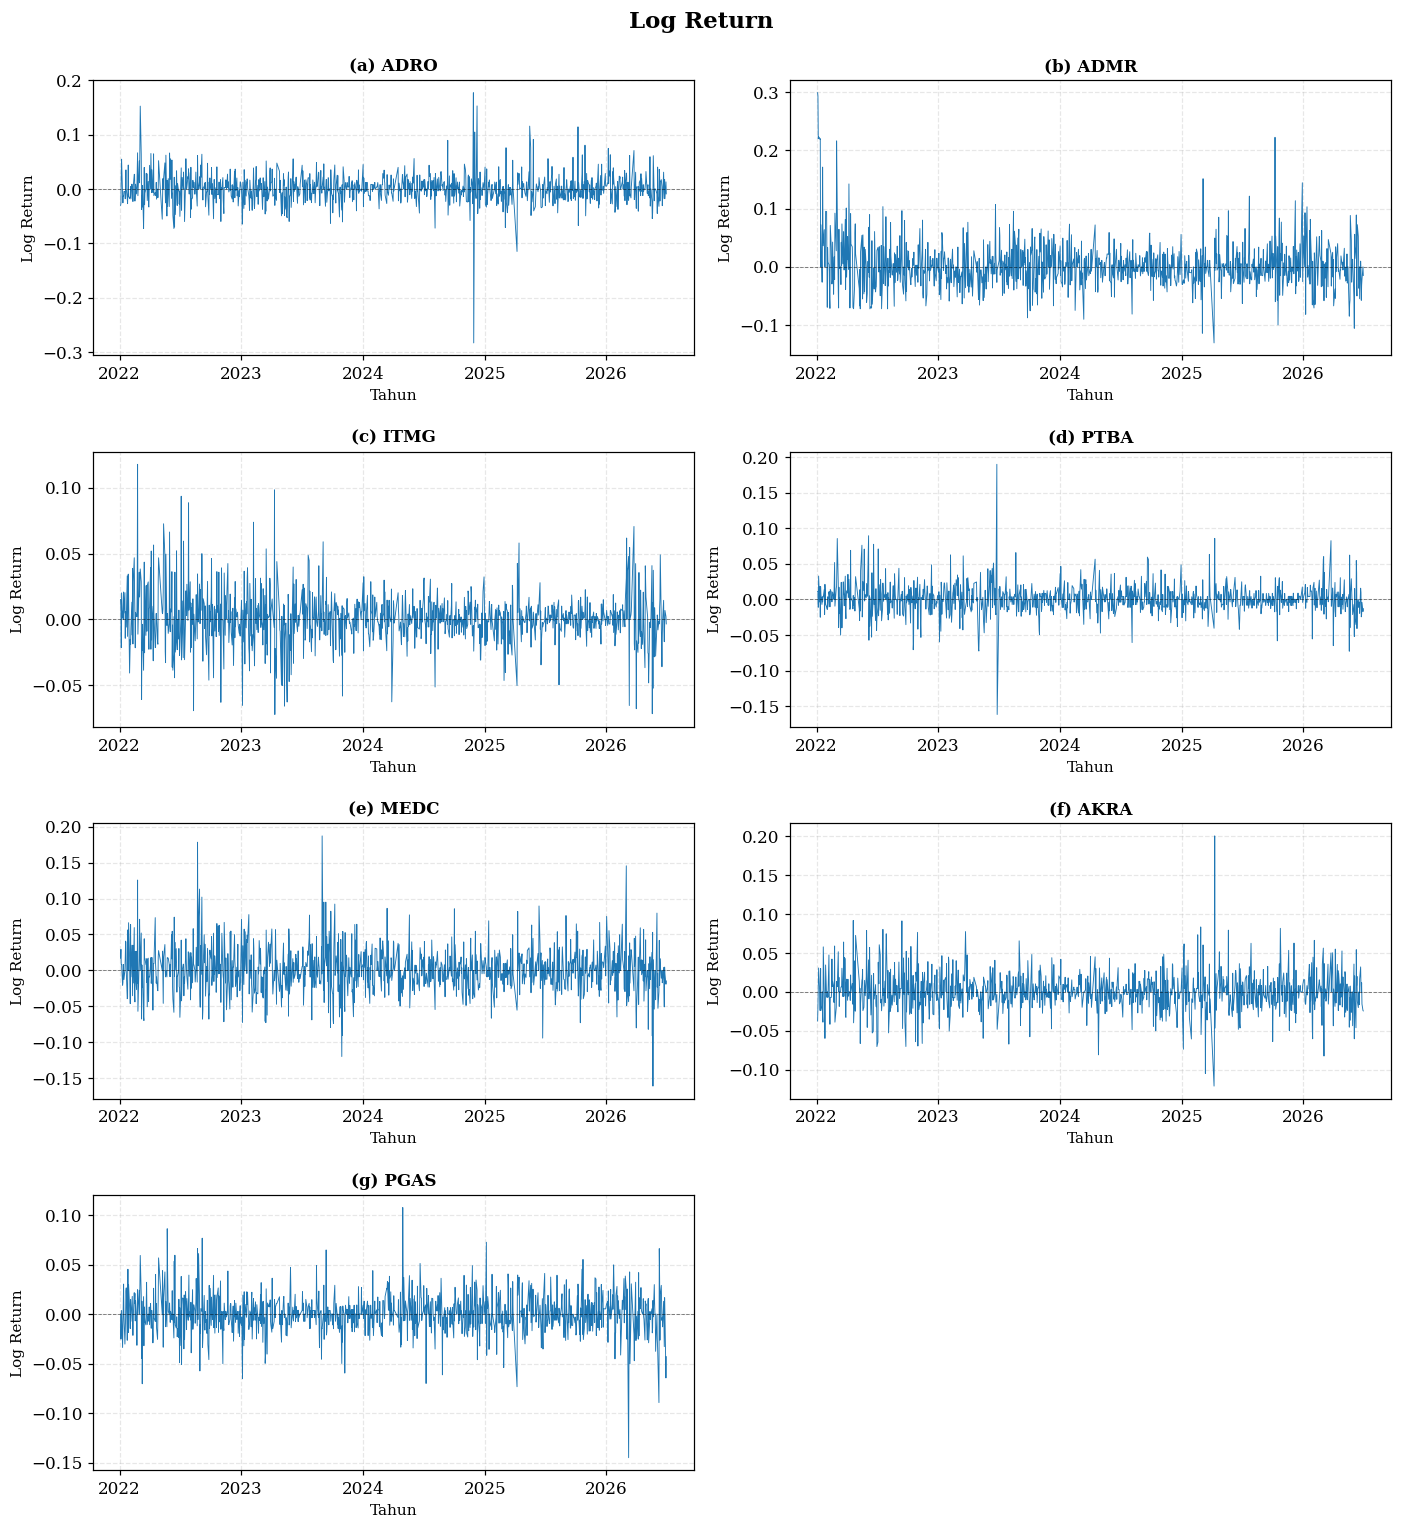

💾 Gambar berhasil disimpan!
   Lokasi : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\gambar_4_2_log_return.png


In [7]:
LABEL_PANEL = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)', '(g)']
plt.rcParams.update({'font.family': 'serif'})
fig, axes = plt.subplots(4, 2, figsize=(13, 14))
axes = axes.flatten()
for i, kode in enumerate(URUTAN_EMITEN):
    sub = df[df['Kode_Emiten'] == kode].copy()
    sub['Tanggal'] = pd.to_datetime(sub['Tanggal'])
    sub = sub.sort_values('Tanggal')
    ax = axes[i]
    ax.plot(sub['Tanggal'], sub['Log_Return'], color='tab:blue', linewidth=0.6)
    ax.axhline(0, color='black', linewidth=0.6, linestyle='--', alpha=0.5)
    ax.set_title(f'{LABEL_PANEL[i]} {kode}', fontweight='bold', fontsize=11)
    ax.set_xlabel('Tahun', fontsize=10)
    ax.set_ylabel('Log Return', fontsize=10)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.grid(True, linestyle='--', alpha=0.3)
axes[-1].axis('off')

# ---- JUDUL DI TENGAH ATAS ----
fig.suptitle('Log Return', fontsize=15, fontweight='bold', y=0.995)

fig.tight_layout(pad=1.5)
fig.subplots_adjust(top=0.95)   # beri ruang agar judul tidak menempel ke panel

path_gambar = OUTPUT_DIR_DASHBOARD / 'gambar_4_2_log_return.png'
fig.savefig(path_gambar, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('=' * 80)
print('💾 Gambar berhasil disimpan!')
print(f'   Lokasi : {path_gambar.resolve()}')
print('=' * 80)

## 4. Fitur Teknikal: RSI (Relative Strength Index)

RSI mengukur kekuatan momentum harga dalam rentang 0-100:

$$ RSI_t = 100 - \frac{100}{1 + RS_t}, \qquad RS_t = \frac{\text{rata-rata gain}_{14}}{\text{rata-rata loss}_{14}} $$

Dihitung menggunakan metode **Wilder's smoothing** (exponential moving average
dengan `alpha = 1/periode`), sesuai standar perhitungan RSI 14 hari.


In [8]:
# ==============================================================================
# CELL — PERHITUNGAN RELATIVE STRENGTH INDEX (RSI14) REVISED
# ==============================================================================

def hitung_rsi(series, period=RSI_PERIOD):
    """
    Menghitung RSI menggunakan metode standar Wilder's Smoothing (EMA).
    Aman dari pembagian dengan nol (DivisionByZero).
    """
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    # Menggunakan alpha=1/period sesuai standar indikator teknikal orisinal
    avg_gain = gain.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    avg_loss = loss.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

    # Hitung Relative Strength (RS)
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))

    # Penanganan kondisi batas ekstrem (Handling division by zero / flat price)
    rsi = rsi.where(~(avg_loss == 0), 100)
    rsi = rsi.where(~((avg_gain == 0) & (avg_loss == 0)), 50)

    return rsi

print("=" * 70)
print(" ⚙️ MEMULAI PERHITUNGAN INDIKATOR RSI")
print("=" * 70)

# Pastikan data terurut kronologis sebelum kalkulasi runtun waktu
df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# Eksekusi kalkulasi RSI per kelompok emiten dengan melemparkan fungsi langsung
# Pendekatan ini mempertahankan struktur indeks asli df tanpa risiko pergeseran baris
df['RSI'] = df.groupby('Kode_Emiten')['Adj Close'].transform(hitung_rsi, period=RSI_PERIOD)

# Sinkronisasi nama kolom dengan konfigurasi tesis awal (KOLOM_X1 menggunakan RSI14)
df['RSI14'] = df['RSI']

print(f"  ✅ RSI ({RSI_PERIOD} hari) sukses dihitung untuk semua emiten.")
print(f"  Total NaN pada fitur RSI14: {df['RSI14'].isna().sum()} baris awal (warm-up)")
print("-" * 70)

# Pembentukan tabel pivot visual monitoring laporan data akhir
tabel_rsi = (
    df[['Tanggal', 'Kode_Emiten', 'RSI14']]
      .dropna(subset=['RSI14'])
      .sort_values(['Tanggal', 'Kode_Emiten'])
      .pivot(index='Tanggal', columns='Kode_Emiten', values='RSI14')
      .reindex(columns=URUTAN_EMITEN)
)

# Menampilkan 5 baris teratas tabel pivot di lingkungan notebook
display(tabel_rsi.head())


 ⚙️ MEMULAI PERHITUNGAN INDIKATOR RSI
  ✅ RSI (14 hari) sukses dihitung untuk semua emiten.
  Total NaN pada fitur RSI14: 98 baris awal (warm-up)
----------------------------------------------------------------------


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-21,24.416975,96.226018,82.541657,79.099816,87.601155,22.101710,47.806253
2022-01-24,23.005393,96.523416,85.819527,81.132468,73.307907,21.769494,40.106495
2022-01-25,21.040467,96.523416,79.504169,70.116799,63.297902,20.445653,38.212730
2022-01-26,21.040467,96.523416,80.488179,73.928868,70.130457,17.819849,52.657065
2022-01-27,32.229116,96.523416,84.027483,75.604585,70.130457,16.787896,47.657812


## 5. Fitur Teknikal: Moving Average (MA)

Simple Moving Average (SMA) dihitung untuk beberapa periode (5, 10, 20 hari)
sebagai indikator tren harga jangka pendek-menengah:

$$ MA_t^{(n)} = \frac{1}{n}\sum_{i=0}^{n-1} P_{t-i} $$


In [9]:
# ==============================================================================
# CELL — PERHITUNGAN SIMPLE MOVING AVERAGE (MA5, MA10, MA20) REVISED
# ==============================================================================

# 1. Perhitungan Moving Average secara Efisien Tanpa Lambda
for window in MA_WINDOWS:
    # Menggunakan nama kolom tanpa underscore (MA5, MA10, MA20) sesuai KOLOM_X1
    col_name = f'MA{window}'
    
    # Memanggil method rolling langsung di dalam transform untuk efisiensi memori
    df[col_name] = (
        df.groupby('Kode_Emiten')['Adj Close']
          .transform(lambda x: x.rolling(window=window, min_periods=window).mean())
    )

# Perbarui daftar nama kolom MA beraliansi dengan konfigurasi tesis awal
ma_cols = [f'MA{w}' for w in MA_WINDOWS]

print("=" * 80)
print(" ⚙️ MEMULAI GENERASI TABEL MONITORING MOVING AVERAGE")
print("=" * 80)

# 2. Pembuatan Tabel Terpisah per Jenis MA: Baris=Tanggal, Kolom=7 Emiten
tabel_ma = {}
for ma in ma_cols:
    tabel = (
        df.pivot(index='Tanggal', columns='Kode_Emiten', values=ma)
          .reindex(columns=URUTAN_EMITEN)
    )
    tabel_ma[ma] = tabel.dropna(how='all')  # Buang baris awal yang seluruhnya NaN

    print("=" * 80)
    print(f" 📊 TABEL {ma} - 7 EMITEN KANDIDAT TESIS")
    print("=" * 80)
    
    # Menampilkan gabungan 5 baris pertama dan 5 baris terakhir untuk ringkasan laporan
    display(pd.concat([
        tabel_ma[ma].head(5),
        tabel_ma[ma].tail(5)
    ]).round(2))
    print(f"  Total NaN pada fitur {ma}: {df[ma].isna().sum()} baris awal (warm-up)")
    print()


 ⚙️ MEMULAI GENERASI TABEL MONITORING MOVING AVERAGE
 📊 TABEL MA5 - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-07,786.92,230.97,9275.28,1194.04,392.52,615.07,874.48
2022-01-10,788.95,293.86,9315.00,1203.70,395.80,613.32,863.02
2022-01-11,791.65,369.55,9338.37,1215.13,396.46,613.32,849.66
2022-01-12,796.38,460.64,9350.05,1217.76,395.47,612.74,841.38
2022-01-13,795.03,540.60,9441.17,1227.43,393.84,614.63,840.11
2026-06-24,2262.00,1522.00,22270.00,2447.56,1126.00,1249.00,1540.00
2026-06-25,2268.00,1481.00,22200.00,2428.55,1107.00,1266.00,1532.00
2026-06-26,2274.00,1451.00,22165.00,2417.10,1090.00,1275.00,1528.00
2026-06-29,2272.00,1418.00,22075.00,2390.00,1068.00,1270.00,1501.00


  Total NaN pada fitur MA5: 28 baris awal (warm-up)

 📊 TABEL MA10 - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-14,785.57,423.82,9389.77,1212.49,391.54,612.45,856.34
2022-01-17,781.85,482.72,9459.86,1218.64,392.36,607.94,849.98
2022-01-18,779.14,535.41,9501.91,1223.91,393.18,605.75,842.34
2022-01-19,778.81,595.33,9543.97,1227.43,394.49,602.92,836.61
2022-01-20,779.14,655.25,9600.04,1232.70,397.11,597.31,833.75
2026-06-24,2279.00,1545.00,22510.00,2484.97,1152.93,1245.00,1541.00
2026-06-25,2278.00,1530.50,22500.00,2460.18,1143.08,1250.00,1539.00
2026-06-26,2278.00,1520.50,22470.00,2444.89,1130.77,1250.50,1541.00
2026-06-29,2278.00,1499.50,22332.50,2426.57,1115.50,1249.50,1530.50


  Total NaN pada fitur MA10: 63 baris awal (warm-up)

 📊 TABEL MA20 - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-28,774.92,661.79,9679.47,1230.50,402.15,586.58,846.79
2022-01-31,772.72,714.43,9726.78,1234.46,405.96,581.41,846.16
2022-02-02,771.20,760.95,9759.49,1236.87,408.42,577.23,844.88
2022-02-03,770.86,806.45,9779.94,1238.85,411.73,573.63,845.36
2022-02-04,768.83,849.63,9807.39,1240.83,414.68,569.55,846.00
2026-06-24,2269.00,1504.00,22355.00,2535.68,1180.87,1244.25,1585.13
2026-06-25,2268.50,1498.25,22313.75,2518.50,1173.02,1244.25,1573.30
2026-06-26,2266.00,1491.00,22280.00,2500.83,1164.93,1243.25,1561.47
2026-06-29,2265.00,1483.75,22248.75,2481.16,1155.83,1240.75,1544.89


  Total NaN pada fitur MA20: 133 baris awal (warm-up)



## 6. Fitur Teknikal: Stochastic Oscillator

Stochastic Oscillator mengukur posisi harga penutupan relatif terhadap
rentang harga tertinggi-terendah dalam periode tertentu:

$$ \%K_t = 100 \times \frac{C_t - L_{n}}{H_{n} - L_{n}} $$

$$ \%D_t = SMA(\%K_t, m) $$

dengan `H_n` dan `L_n` adalah harga tertinggi (`High`) dan terendah (`Low`)
selama `n` hari terakhir (`STOCH_PERIOD`), dan `%D` adalah SMA dari `%K`
selama `m` hari (`STOCH_SMOOTH_D`).


In [10]:
# ==============================================================================
# CELL — PERHITUNGAN STOCHASTIC OSCILLATOR (Stoch_K & Stoch_D)
# ==============================================================================

def hitung_stochastic(group, n=STOCH_PERIOD, m=STOCH_SMOOTH_D):
    """Hitung %K dan %D Stochastic Oscillator untuk satu grup emiten."""
    lowest_low   = group['Low'].rolling(window=n, min_periods=n).min()
    highest_high = group['High'].rolling(window=n, min_periods=n).max()

    # Menggunakan denominator untuk mengantisipasi saham flat (pembagian dengan nol)
    denom = highest_high - lowest_low
    percent_k = 100 * (group['Adj Close'] - lowest_low) / denom
    percent_k = percent_k.where(denom != 0, 50.0)
    
    percent_d = percent_k.rolling(window=m, min_periods=m).mean()

    # Nama kolom disesuaikan dengan KOLOM_X1 di konfigurasi awal (tanpa simbol %)
    return pd.DataFrame({'Stoch_K': percent_k, 'Stoch_D': percent_d}, index=group.index)

print("=" * 80)
print(" ⚙️ MEMULAI PERHITUNGAN INDIKATOR STOCHASTIC OSCILLATOR")
print("=" * 80)

# Memastikan urutan data runtun waktu panel aman
df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# Eksekusi fungsi per grup emiten
stoch_result = (
    df.groupby('Kode_Emiten', group_keys=False)
      .apply(lambda g: hitung_stochastic(g, n=STOCH_PERIOD, m=STOCH_SMOOTH_D))
)

df['Stoch_K'] = stoch_result['Stoch_K']
df['Stoch_D'] = stoch_result['Stoch_D']

print(f"  ✅ Stochastic Oscillator (K={STOCH_PERIOD}, D=SMA {STOCH_SMOOTH_D}) sukses dihitung.")
print(f"  Total NaN pada fitur Stoch_K: {df['Stoch_K'].isna().sum()} baris awal (warm-up)")

for metric, nama in [('Stoch_K', '%K'), ('Stoch_D', '%D')]:
    tabel = (
        df.pivot(index='Tanggal', columns='Kode_Emiten', values=metric)
          .reindex(columns=URUTAN_EMITEN)
          .dropna(how='all')
    )

    tabel_fmt = tabel.round(2).astype(object)
    tabel_display = pd.concat([
        tabel_fmt.head(5),
        pd.DataFrame([['...'] * len(tabel_fmt.columns)],
                      columns=tabel_fmt.columns,
                      index=['...']),
        tabel_fmt.tail(5)
    ])
    
    tabel_display.index = tabel_display.index.map(
        lambda x: x.strftime('%Y-%m-%d') if hasattr(x, 'strftime') else x
    )
    tabel_display.index.name = 'Tanggal'

    print("\n" + "=" * 80)
    print(f" 📊 TABEL STOCHASTIC OSCILLATOR {nama} - 7 EMITEN KANDIDAT TESIS")
    print("=" * 80)
    display(tabel_display)

# ═════════════════════════════════
# TABEL RASIO MA & Volume Z-Score)
# ═════════════════════════════════
g = df.groupby('Kode_Emiten', group_keys=False)

# Rasio MA (berpusat nol, sebanding antaremiten) → Tabel 4.7
for n in [5, 10, 20]:
    df[f'MA{n}_Ratio'] = df['Adj Close'] / df[f'MA{n}'] - 1

# Volume Z-Score per emiten
df['Volume_ZScore'] = g['Volume'].transform(lambda s: (s - s.mean()) / s.std())

print("\n" + "=" * 80)
print("  FITUR TABEL RASIO MA & Volume Z-Score")
print("=" * 80)
print(df[['MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'Volume_ZScore']]
      .describe().round(4).to_string())


 ⚙️ MEMULAI PERHITUNGAN INDIKATOR STOCHASTIC OSCILLATOR
  ✅ Stochastic Oscillator (K=14, D=SMA 3) sukses dihitung.
  Total NaN pada fitur Stoch_K: 91 baris awal (warm-up)

 📊 TABEL STOCHASTIC OSCILLATOR %K - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-20,-463.06,84.8,-451.49,-486.13,-44.52,-151.95,-268.4
2022-01-21,-482.47,87.84,-517.41,-581.98,-53.02,-127.14,-254.48
2022-01-24,-487.13,88.7,-487.37,-608.34,-82.48,-129.9,-306.74
2022-01-25,-455.8,87.46,-432.91,-619.8,-104.82,-140.92,-378.96
2022-01-26,-455.8,86.08,-467.49,-757.47,-70.07,-123.42,-361.47
...,...,...,...,...,...,...,...
2026-06-24,58.33,40.7,21.93,5.26,4.0,75.0,32.95
2026-06-25,75.0,20.0,19.3,2.38,7.84,83.33,60.71
2026-06-26,58.33,12.0,24.56,8.7,5.88,72.22,64.15



 📊 TABEL STOCHASTIC OSCILLATOR %D - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-24,-477.55,87.11,-485.42,-558.82,-60.01,-136.33,-276.54
2022-01-25,-475.13,88.0,-479.23,-603.38,-80.11,-132.65,-313.39
2022-01-26,-466.24,87.42,-462.59,-661.87,-85.79,-131.41,-349.05
2022-01-27,-452.16,85.81,-447.64,-714.53,-81.65,-121.69,-372.12
2022-01-28,-449.62,85.77,-425.94,-764.91,-53.53,-106.35,-349.28
...,...,...,...,...,...,...,...
2026-06-24,68.44,54.26,33.04,5.83,6.92,74.52,38.25
2026-06-25,69.44,40.39,25.44,7.05,5.28,78.49,44.63
2026-06-26,63.89,24.23,21.93,5.45,5.91,76.85,52.61



  FITUR TABEL RASIO MA & Volume Z-Score
       MA5_Ratio  MA10_Ratio  MA20_Ratio  Volume_ZScore
count  7490.0000   7455.0000   7385.0000      7518.0000
mean      0.0019      0.0040      0.0081        -0.0000
std       0.0305      0.0444      0.0641         0.9996
min      -0.1354     -0.1908     -0.2324        -1.3778
25%      -0.0127     -0.0187     -0.0261        -0.5706
50%       0.0007      0.0015      0.0047        -0.2843
75%       0.0147      0.0243      0.0383         0.2265
max       0.5261      0.7290      0.6489        15.0561


In [11]:
# TABEL 4.7 — Rasio MA (agregat)
t47 = df[['MA5_Ratio','MA10_Ratio','MA20_Ratio']].describe().T[['mean','std','min','max']].round(6)
t47.columns = ['Mean','Std','Min','Maks']

# TABEL 4.8 — Autoregresif volatilitas (agregat)
fitur_ar = ['Vol_Lag1','Vol_Lag2','Vol_Lag3','Vol_MA5','Vol_STD5']
t48 = df[fitur_ar].describe().T[['mean','std','min','max']].round(6)
t48.columns = ['Mean','Std','Min','Maks']

# TABEL 4.9 — Volume Z-Score per emiten
t49 = df.groupby('Kode_Emiten')['Volume_ZScore'].agg(['mean','std','min','max']).reindex(URUTAN_EMITEN).round(4)
t49.columns = ['Mean','Std','Min','Maks']

for nama, t in [('TABEL Statistik Deskriptif Rasio MA', t47), ('TABEL Statistik Deskriptif Autoregresif Volatilitas', t48), ('TABEL Statistik Deskriptif Volume Z-Score', t49)]:
    print(f'\n=== {nama} ===')
    print(t.to_string())


=== TABEL Statistik Deskriptif Rasio MA ===


                Mean       Std       Min      Maks
MA5_Ratio   0.001909  0.030512 -0.135447  0.526104
MA10_Ratio  0.003978  0.044381 -0.190803  0.729044
MA20_Ratio  0.008098  0.064098 -0.232395  0.648922

=== TABEL Statistik Deskriptif Autoregresif Volatilitas ===
              Mean       Std       Min      Maks
Vol_Lag1  0.024370  0.011265  0.004436  0.110206
Vol_Lag2  0.024364  0.011265  0.004436  0.110206
Vol_Lag3  0.024359  0.011265  0.004436  0.110206
Vol_MA5   0.024385  0.011161  0.005009  0.110206
Vol_STD5  0.001422  0.001744  0.000002  0.028515

=== TABEL Statistik Deskriptif Volume Z-Score ===
             Mean  Std     Min     Maks
Kode_Emiten                            
ADRO         -0.0  1.0 -1.0973  11.7701
ADMR          0.0  1.0 -0.8076  15.0561
ITMG         -0.0  1.0 -1.0712   9.2375
PTBA         -0.0  1.0 -0.8615  11.2492
MEDC         -0.0  1.0 -1.0171  11.2839
AKRA          0.0  1.0 -1.3778  13.7448
PGAS         -0.0  1.0 -1.1367   9.3132


## 7. Ringkasan Dataset Hasil Preprocessing

Menampilkan struktur akhir dataset (`technical_features.csv`) berisi seluruh
fitur teknikal X1 dan variabel Y, beserta pemeriksaan jumlah `NaN` per kolom.


In [12]:
# ==============================================================================
# CELL — PEMBENTUKAN DATAFRAME FINAL & QUALITY CONTROL HASIL TEKNIKAL
# ==============================================================================

# 1. Sesuaikan daftar kolom fitur dengan nama variabel terbaru yang valid di df
# Menggunakan MA tanpa underscore, Stoch_K, Stoch_D, serta menyertakan fitur sisa (EMA, BB, MACD, Volume)
ma_cols_baku = ['MA5', 'MA10', 'MA20']
fitur_sisa_baku = ['EMA12', 'EMA26', 'BB_Upper', 'BB_Lower', 'BB_Width', 'BB_PctB', 
                    'Volume_Change', 'Volume_MA5', 'MACD', 'MACD_Signal', 'MACD_Hist', 'Target_Volatility']

kolom_fitur = [
    'Tanggal', 'Kode_Emiten', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume',
    'Log_Return', 'Volatilitas_Return', 'RSI', 'RSI14', 'Stoch_K', 'Stoch_D'
] + ma_cols_baku + fitur_sisa_baku

# Tambahkan Nama_Perusahaan hanya jika kolom tersebut eksis di dataframe mentah Anda
if 'Nama_Perusahaan' in df.columns:
    kolom_fitur.insert(2, 'Nama_Perusahaan')

# 2. Validasi Keberadaan Kolom (Data Quality Assurance)
missing_cols = [c for c in kolom_fitur if c not in df.columns]
if missing_cols:
    # Remove missing columns from the list instead of raising an error
    kolom_fitur = [c for c in kolom_fitur if c in df.columns]
    print(f"⚠️  Kolom berikut tidak tersedia (diabaikan): {missing_cols}")

# 3. Potong DataFrame Sesuai Fitur yang Diperlukan Proyek Tesis
df_final = df[kolom_fitur].copy()

# 4. Tampilkan Laporan Ringkasan Hasil Preprocessing (Format Standar Indonesia)
print("=" * 70)
print(" 📊 RINGKASAN DATASET HASIL PREPROCESSING TEKNIKAL FINAL")
print("=" * 70)
print(f"  Total baris  : {len(df_final):,}".replace(",", "."))
print(f"  Total kolom  : {len(df_final.columns)}")

# Amankan penarikan komponen tanggal murni (.date()) baik dari format teks maupun datetime
t_min = pd.to_datetime(df_final['Tanggal'].min()).date()
t_max = pd.to_datetime(df_final['Tanggal'].max()).date()
print(f"  Periode      : {t_min} s/d {t_max}")
print("-" * 70)
print("  Jumlah NaN per kolom (Masa Warm-Up Indikator Valid):")

nan_summary = df_final.isna().sum()
nan_summary = nan_summary[nan_summary > 0]

if len(nan_summary) == 0:
    print("    (Hebat! Tidak ada nilai NaN yang tersisa di dataset)")
else:
    for col, n_nan in nan_summary.items():
        print(f"    {col:24s}: {n_nan:,} baris".replace(",", "."))
print("=" * 70)


⚠️  Kolom berikut tidak tersedia (diabaikan): ['EMA12', 'EMA26', 'BB_Upper', 'BB_Lower', 'BB_Width', 'BB_PctB', 'Volume_Change', 'Volume_MA5', 'MACD', 'MACD_Signal', 'MACD_Hist']
 📊 RINGKASAN DATASET HASIL PREPROCESSING TEKNIKAL FINAL
  Total baris  : 7.518
  Total kolom  : 18
  Periode      : 2022-01-03 s/d 2026-06-30
----------------------------------------------------------------------
  Jumlah NaN per kolom (Masa Warm-Up Indikator Valid):
    Log_Return              : 7 baris
    Volatilitas_Return      : 140 baris
    RSI                     : 98 baris
    RSI14                   : 98 baris
    Stoch_K                 : 91 baris
    Stoch_D                 : 105 baris
    MA5                     : 28 baris
    MA10                    : 63 baris
    MA20                    : 133 baris
    Target_Volatility       : 140 baris


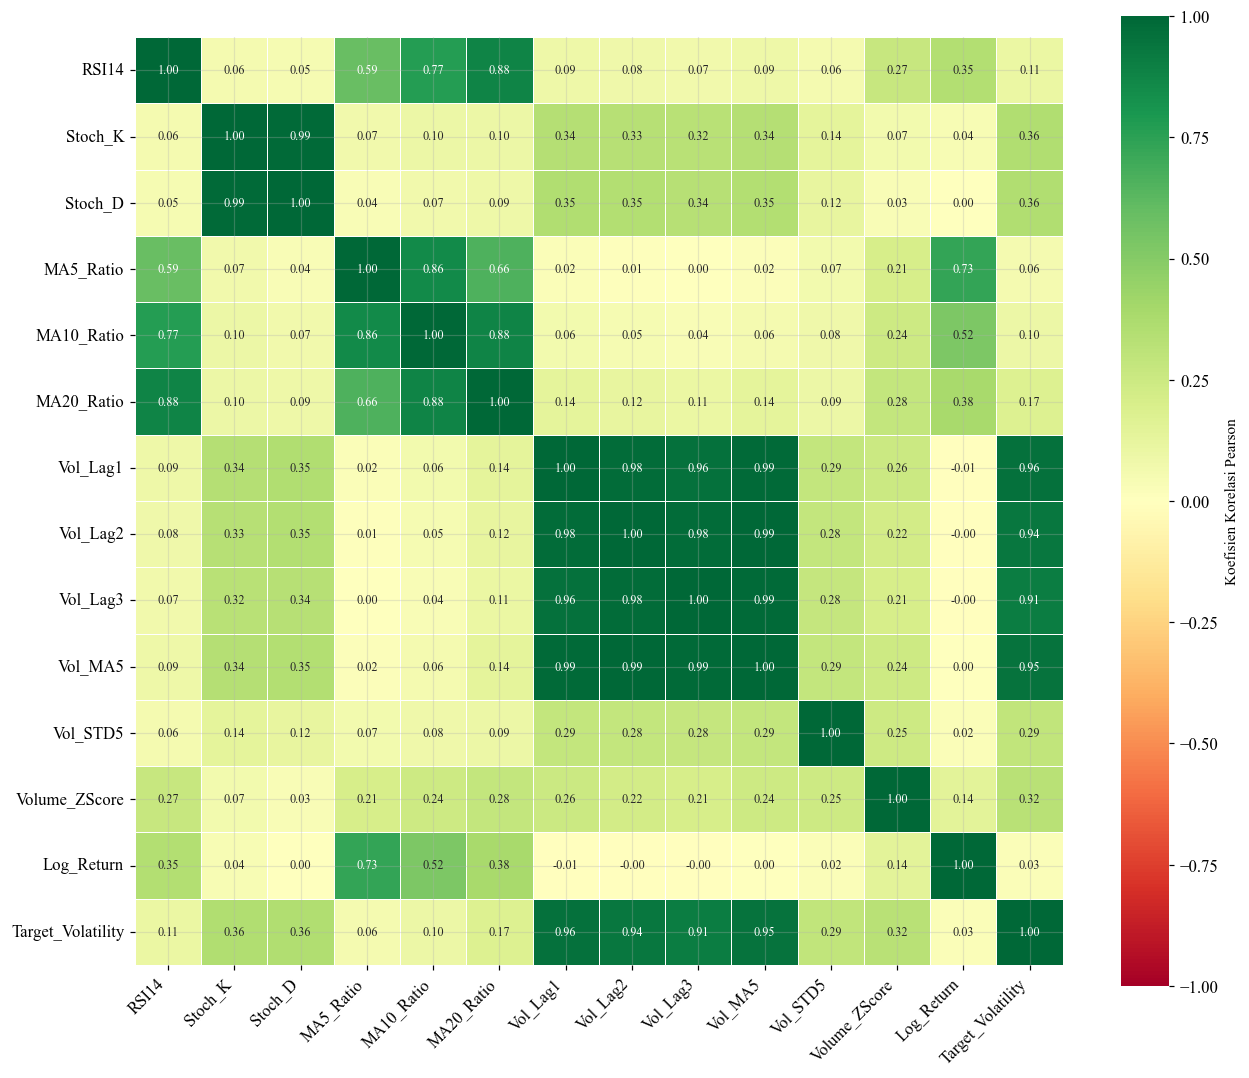

Korelasi fitur terhadap Target_Volatility (urut |r|):
Vol_Lag1         0.9607
Vol_MA5          0.9513
Vol_Lag2         0.9363
Vol_Lag3         0.9111
Stoch_D          0.3589
Stoch_K          0.3552
Volume_ZScore    0.3216
Vol_STD5         0.2918
MA20_Ratio       0.1738
RSI14            0.1050
MA10_Ratio       0.0961
MA5_Ratio        0.0559
Log_Return       0.0276


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

kolom_x1 = [
    'RSI14', 'Stoch_K', 'Stoch_D',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio',
    'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'Volume_ZScore', 'Log_Return',
]
kolom_plot = kolom_x1 + ['Target_Volatility']

korr = df[kolom_plot].corr()

plt.rcParams.update({'font.family': 'Times New Roman'})
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(korr, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            annot_kws={'size': 8},
            cbar_kws={'label': 'Koefisien Korelasi Pearson'}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

path = OUTPUT_DIR_DASHBOARD / 'gambar_4_x_korelasi_fitur.png'
fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Peringkat korelasi terhadap target → bahan narasi
print('Korelasi fitur terhadap Target_Volatility (urut |r|):')
print(korr['Target_Volatility'].drop('Target_Volatility')
      .sort_values(key=abs, ascending=False).round(4).to_string())

## 8. Visualisasi Volatilitas Return Saham (Gambar 4.2)

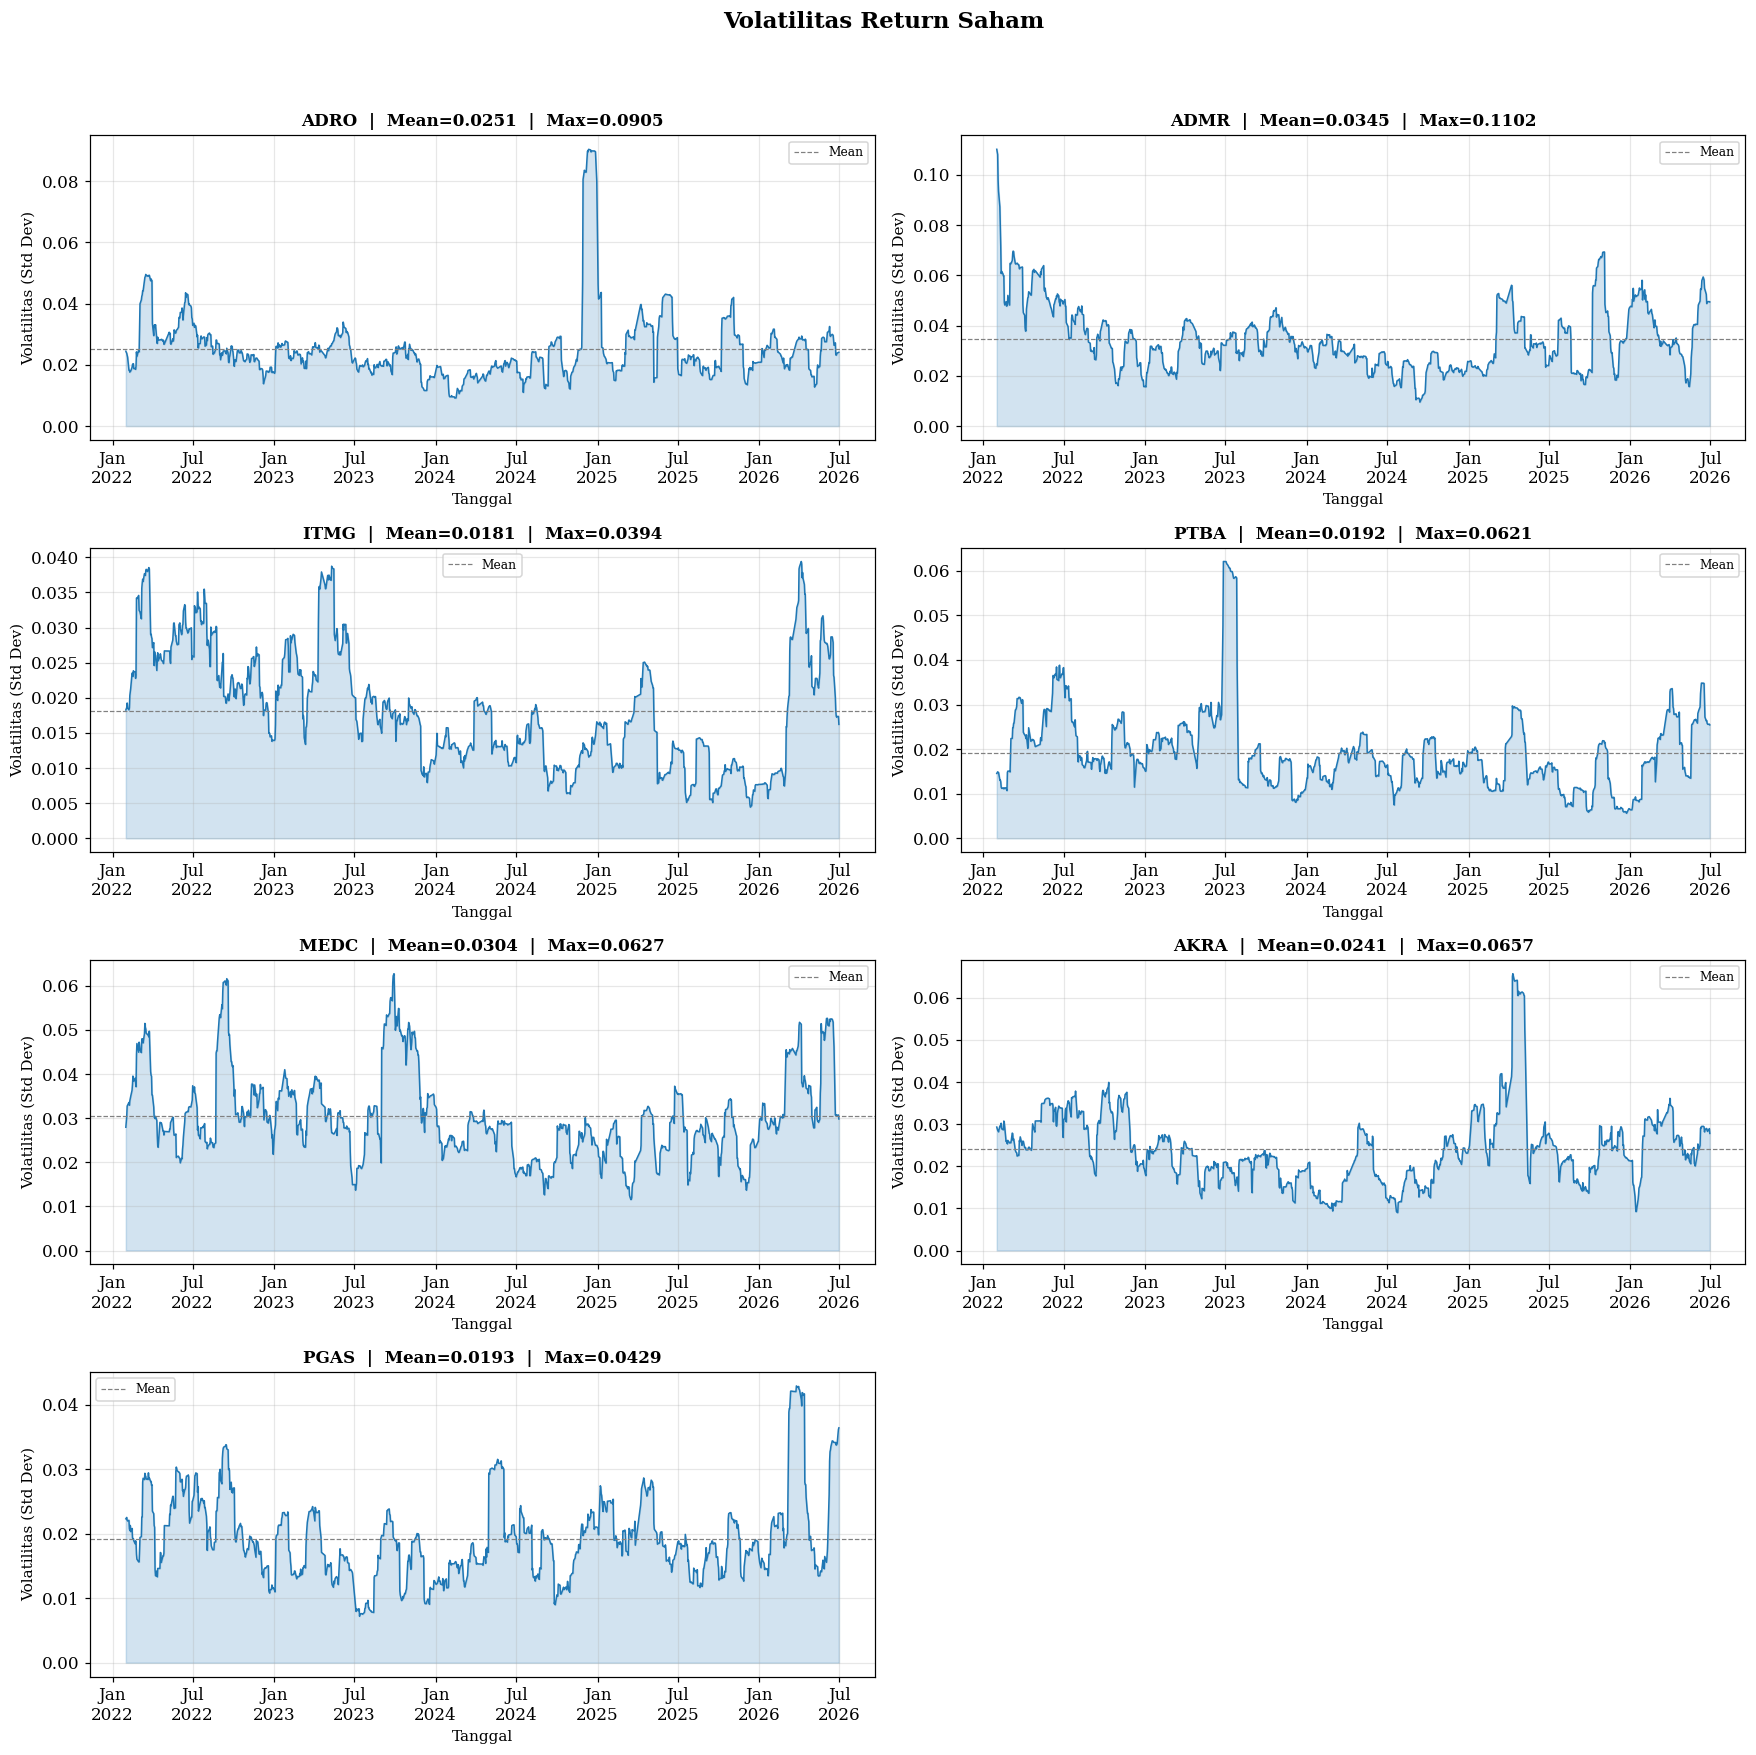

Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\gambar_volatilitas_return_per6bulan.png


In [22]:
fig, axes = plt.subplots(4, 2, figsize=(16, 16))
axes = axes.flatten()

# ---- JUDUL RINGKAS DI TENGAH ATAS ----
fig.suptitle('Volatilitas Return Saham', fontsize=15, fontweight='bold', y=0.995)

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    df_e = df[df['Kode_Emiten'] == kode].dropna(subset=['Volatilitas_Return'])

    ax.plot(df_e['Tanggal'], df_e['Volatilitas_Return'],
            color='tab:blue', linewidth=1.0)
    ax.fill_between(df_e['Tanggal'], df_e['Volatilitas_Return'],
                    alpha=0.2, color='tab:blue')

    vol_mean = df_e['Volatilitas_Return'].mean()
    vol_max  = df_e['Volatilitas_Return'].max()
    ax.axhline(vol_mean, color='gray', linestyle='--', linewidth=0.8, label='Mean')

    ax.set_title(f'{kode}  |  Mean={vol_mean:.4f}  |  Max={vol_max:.4f}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Tanggal')
    ax.set_ylabel('Volatilitas (Std Dev)')

    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))

    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

axes[-1].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.97])

path_gambar = OUTPUT_DIR_DASHBOARD / 'gambar_volatilitas_return_per6bulan.png'
plt.savefig(path_gambar, dpi=150, bbox_inches='tight')
plt.show()

print(f"Gambar disimpan: {path_gambar}")

## 9. Heatmap Korelasi Volatilitas Antar Emiten (Gambar 4.3)

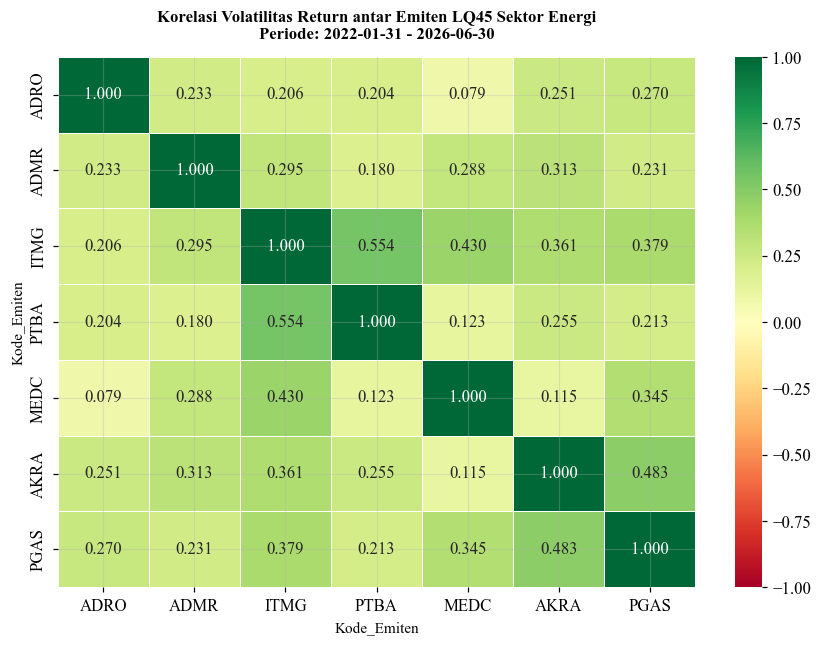

Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\gambar_heatmap_korelasi_volatilitas.png


In [15]:
import seaborn as sns

# Pivot volatilitas return: baris=Tanggal, kolom=7 Emiten
df_pivot_vol = (
    df.pivot_table(index='Tanggal', columns='Kode_Emiten', values='Volatilitas_Return')
      .reindex(columns=URUTAN_EMITEN)
      .dropna()
)

corr_vol = df_pivot_vol.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_vol, annot=True, fmt='.3f', cmap='RdYlGn',
    center=0, linewidths=0.5, vmin=-1, vmax=1, ax=ax
)
ax.set_title(
    f'Korelasi Volatilitas Return antar Emiten LQ45 Sektor Energi\n'
    f'Periode: {df_pivot_vol.index.min().date()} - {df_pivot_vol.index.max().date()}',
    fontweight='bold', pad=12
)
plt.tight_layout()

path_heatmap = OUTPUT_DIR_DASHBOARD / 'gambar_heatmap_korelasi_volatilitas.png'
plt.savefig(path_heatmap, dpi=150, bbox_inches='tight')
plt.show()

print(f"Gambar disimpan: {path_heatmap}")

## 10. Penanganan Baris dengan Nilai NaN

Baris-baris awal pada setiap emiten yang mengandung `NaN` (akibat perhitungan
rolling/lag) **dihapus**, karena belum memiliki nilai fitur teknikal maupun
volatilitas yang valid. Jumlah baris yang hilang per emiten setara dengan
periode rolling terbesar (Stochastic Oscillator, `STOCH_PERIOD` hari).


In [16]:
# ==============================================================================
# CELL — REVISI PEMBERSIHAN BARIS KOSONG (DROPNA MASA WARM-UP)
# ==============================================================================

# 1. Hitung dimensi baris awal sebelum reduksi data panel
jumlah_sebelum = len(df_final)

# 2. Hapus baris yang mengandung NaN (masa warm-up indikator teknikal/lag volatilitas)
df_final_clean = df_final.dropna().reset_index(drop=True)

# 3. Hitung dimensi akhir pasca pembersihan
jumlah_sesudah = len(df_final_clean)
jumlah_dihapus = jumlah_sebelum - jumlah_sesudah
persentase_dihapus = (jumlah_dihapus / jumlah_sebelum * 100) if jumlah_sebelum > 0 else 0

# 4. Format string cetak ke standar pemisah ribuan Indonesia (titik)
str_sebelum = f"{jumlah_sebelum:,}".replace(",", ".")
str_sesudah = f"{jumlah_sesudah:,}".replace(",", ".")
str_dihapus = f"{jumlah_dihapus:,}".replace(",", ".")

print("=" * 70)
print(" ⚙️ LAPORAN REDUKSI OBSERVASI MASA WARM-UP INDIKATOR")
print("=" * 70)
print(f"  Jumlah baris sebelum : {str_sebelum} baris")
print(f"  Jumlah baris sesudah : {str_sesudah} baris (siap untuk modeling)")
print(f"  Jumlah baris dihapus : {str_dihapus} baris ({persentase_dihapus:.2f}%)")
print("-" * 70)

# 5. Tampilkan Distribusi Observasi Valid Tersisa per Emiten Energi
print("  Jumlah observasi siap pakai per emiten:")

# Pastikan daftar urutan emiten ada di locals untuk menghindari NameError
if 'URUTAN_EMITEN' not in locals():
    URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

# Menampilkan counts dengan reindex yang aman dari kategori kosong
sebaran_emiten = df_final_clean['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).fillna(0).astype(int)

# Tampilkan dalam bentuk series yang rapi di notebook
display(sebaran_emiten)
print("=" * 70)


 ⚙️ LAPORAN REDUKSI OBSERVASI MASA WARM-UP INDIKATOR
  Jumlah baris sebelum : 7.518 baris
  Jumlah baris sesudah : 7.371 baris (siap untuk modeling)
  Jumlah baris dihapus : 147 baris (1.96%)
----------------------------------------------------------------------
  Jumlah observasi siap pakai per emiten:


Kode_Emiten
ADRO    1053
ADMR    1053
ITMG    1053
PTBA    1053
MEDC    1053
AKRA    1053
PGAS    1053
Name: count, dtype: int64

## 11. Simpan Dataset Hasil Preprocessing

Menyimpan dataset final (`technical_features.csv`) yang berisi:
- Fitur teknikal **X1**: OHLCV, RSI, MA(5,10,20), Stochastic %K/%D
- Variabel **Y**: Volatilitas Return

File ini menjadi input pada tahap **Integrasi Dataset** (`05_integrasi_dataset.ipynb`),
digabungkan dengan skor sentimen (**X2**) berdasarkan `Tanggal` dan `Kode_Emiten`.


In [17]:
# ⚠️ PENTING: Notebook ini HANYA untuk statistik deskriptif & grafik Bab 4.
# Output disimpan sebagai 'technical_features_DESKRIPTIF.csv' agar TIDAK menimpa
# 'technical_features.csv' milik PREP_01 yang menjadi sumber data pemodelan.

# ==============================================================================
# CELL FINAL — EKSPOR DATASET PREPROCESSING TEKNIKAL KE LOKASI KANONIK
# ==============================================================================

# 1. Gunakan df_final dari sel sebelumnya (menyesuaikan nama df jika df_final_clean belum terbentuk)
df_final_save = df_final.copy() if 'df_final_clean' not in locals() else df_final_clean.copy()

# 2. Amankan konversi tanggal murni menjadi string ISO murni YYYY-MM-DD
# Ini sangat krusial agar file CSV aman dibuka di Excel tanpa merusak format runtun waktu
df_final_save['Tanggal'] = pd.to_datetime(df_final_save['Tanggal']).dt.strftime('%Y-%m-%d')

# 3. Penyelarasan Jalur Penyimpanan Utama (Kanonik Tesis)
# Memastikan objek file target menggunakan variabel penamaan yang seragam
jalur_ekspor_utama = DIR_PROCESSED / F_TEKNIKAL
simpan_csv(df_final_save, jalur_ekspor_utama)

# 4. Salinan Cadangan untuk Kebutuhan Visualisasi Dashboard (Opsional)
if 'OUTPUT_DIR_DASHBOARD' in locals():
    jalur_ekspor_dashboard = OUTPUT_DIR_DASHBOARD / F_TEKNIKAL
    simpan_csv(df_final_save, jalur_ekspor_dashboard)
    print(f"  💾 Salinan dashboard tersimpan -> {jalur_ekspor_dashboard.name}")

# 5. Cetak Laporan Akhir Monitoring Struktur Data (Format Indonesia Berpemisah Titik)
str_baris = f"{len(df_final_save):,}".replace(",", ".")

print("=" * 80)
print(f"  🎉 SUKSES: Berkas Kanonik Teknikal Berhasil Diekspor!")
print("=" * 80)
print(f"  Lokasi File  : {jalur_ekspor_utama}")
print(f"  Total Baris  : {str_baris} baris (siap masuk tahap gabungan/merge)")
print(f"  Total Kolom  : {len(df_final_save.columns)} variabel")
print(f"  Daftar Kolom : {list(df_final_save.columns)}")
print("=" * 80)


OVERWRITE: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features_DESKRIPTIF.csv  (file lama 2026-07-26 23:17 ditimpa)
SAVE  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features_DESKRIPTIF.csv  (7,371 baris)
OVERWRITE: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\technical_features_DESKRIPTIF.csv  (file lama 2026-07-26 23:17 ditimpa)
SAVE  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\technical_features_DESKRIPTIF.csv  (7,371 baris)
  💾 Salinan dashboard tersimpan -> technical_features_DESKRIPTIF.csv
  🎉 SUKSES: Berkas Kanonik Teknikal Berhasil Diekspor!
  Lokasi File  : e:\DATA PEN

## DATA PENDUKUNG: NARASI DI BAB 4 TERKAIT ADMR
Volatilitas tinggi ADMR pada awal 2022 disebabkan oleh periode awal pencatatan saham, di mana pasar belum menemukan titik keseimbangan harga sehingga harga bergerak sangat fluktuatif. Kondisi ini diperkuat oleh lonjakan volume perdagangan yang tinggi pada masa IPO, yang tercermin pada nilai Volume Z-Score ADMR yang mencapai maksimum tertinggi di antara seluruh emiten. Hubungan antara lonjakan volume dan volatilitas ini justru menegaskan relevansi volume sebagai salah satu prediktor volatilitas dalam penelitian.

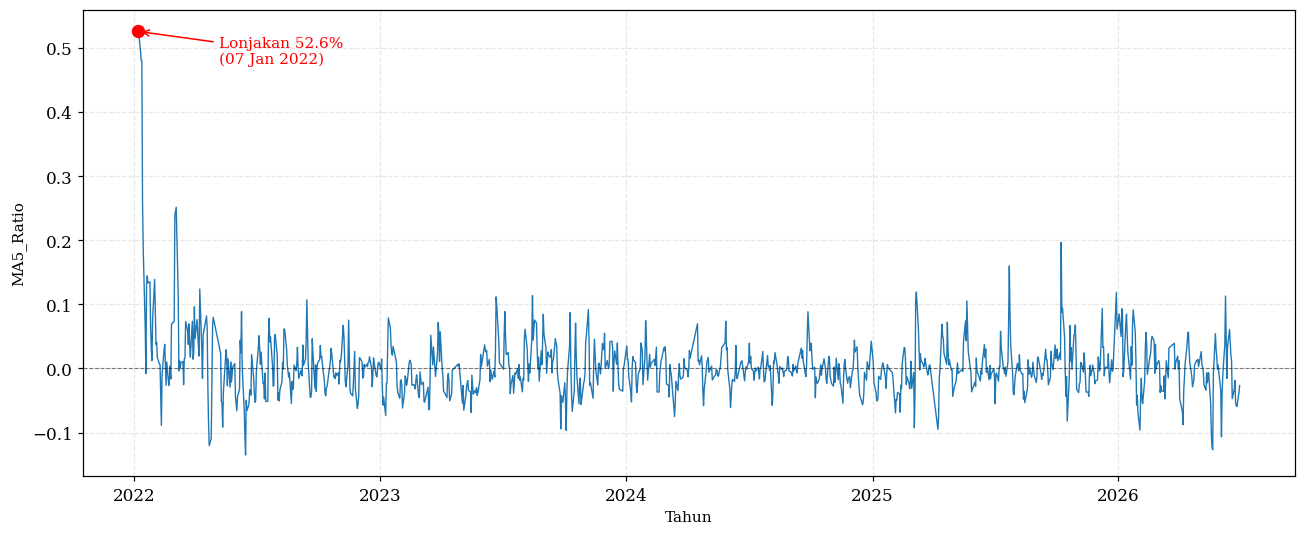

Lonjakan maksimum: 52.6% pada 07 January 2022


In [18]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({'font.family': 'serif'})

sub = df[df['Kode_Emiten'] == 'ADMR'].copy()
sub['Tanggal'] = pd.to_datetime(sub['Tanggal'])
sub = sub.sort_values('Tanggal')

fig, ax = plt.subplots(figsize=(12, 5))

# Garis MA5_Ratio
ax.plot(sub['Tanggal'], sub['MA5_Ratio'], color='tab:blue', linewidth=0.9)

# Garis nol (harga tepat di tren)
ax.axhline(0, color='black', linestyle='--', linewidth=0.7, alpha=0.5)

# Sorot titik maksimum (lonjakan 52%)
idx_max = sub['MA5_Ratio'].idxmax()
tgl_max = sub.loc[idx_max, 'Tanggal']
val_max = sub.loc[idx_max, 'MA5_Ratio']

ax.scatter(tgl_max, val_max, color='red', s=60, zorder=5)
ax.annotate(f'Lonjakan {val_max*100:.1f}%\n({tgl_max:%d %b %Y})',
            xy=(tgl_max, val_max),
            xytext=(tgl_max + pd.Timedelta(days=120), val_max - 0.05),
            fontsize=10, color='red',
            arrowprops=dict(arrowstyle='->', color='red', lw=1))

ax.set_xlabel('Tahun', fontsize=10)
ax.set_ylabel('MA5_Ratio', fontsize=10)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(True, linestyle='--', alpha=0.3)

fig.tight_layout()
path = OUTPUT_DIR_DASHBOARD / 'gambar_4_x_ma5ratio_ADMR.png'
fig.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Lonjakan maksimum: {val_max*100:.1f}% pada {tgl_max:%d %B %Y}")

In [19]:
# Cari emiten & tanggal dengan volatilitas tertinggi
idx = df['Vol_Lag1'].idxmax()
print("Volatilitas maksimum:")
print(f"  Nilai   : {df.loc[idx, 'Vol_Lag1']:.6f}")
print(f"  Emiten  : {df.loc[idx, 'Kode_Emiten']}")
print(f"  Tanggal : {df.loc[idx, 'Tanggal']}")

Volatilitas maksimum:
  Nilai   : 0.110206
  Emiten  : ADMR
  Tanggal : 2022-02-02 00:00:00


In [20]:
# Cek volume ADMR di sekitar tanggal volatilitas tertinggi (2 Feb 2022)
admr = df[df['Kode_Emiten'] == 'ADMR'].copy()
admr['Tanggal'] = pd.to_datetime(admr['Tanggal'])
admr = admr.sort_values('Tanggal')

# Volume Z-Score di bulan pertama
awal = admr[admr['Tanggal'] <= '2022-02-28']
print("Volume Z-Score ADMR Januari–Februari 2022:")
print(f"  Rata-rata : {awal['Volume_ZScore'].mean():.2f}")
print(f"  Maksimum  : {awal['Volume_ZScore'].max():.2f}")
print(f"  Minimum   : {awal['Volume_ZScore'].min():.2f}")
print("  Lonjakan volume terjadi secara terkonsentrasi pada hari-hari awal pencatatan "
      "(puncak Z-score 7,59), "
      "bukan tersebar merata sepanjang periode "
      "(rata-rata dua bulan hanya 0,60).")

Volume Z-Score ADMR Januari–Februari 2022:
  Rata-rata : 0.60
  Maksimum  : 7.59
  Minimum   : -0.81
  Lonjakan volume terjadi secara terkonsentrasi pada hari-hari awal pencatatan (puncak Z-score 7,59), bukan tersebar merata sepanjang periode (rata-rata dua bulan hanya 0,60).


---
## Rekap Output Notebook

| Output | File | Lokasi | Keterangan |
|---|---|---|---|
| Tabel | `tabel_log_return.csv`, `tabel_volatilitas_return.csv` | `03_dataset/raw/` | Pivot lengkap (Tanggal x 7 Emiten) |
| Tabel 4.1 | `tabel_4_1_deskriptif_log_return.csv` | `03_dataset/raw/` | Statistik deskriptif Log Return per emiten |
| Tabel 4.2 | `tabel_4_2_deskriptif_volatilitas.csv` | `03_dataset/raw/` | Statistik deskriptif Volatilitas Return per emiten |
| Gambar 4.1 | `gambar_4_1_log_return.png` | `dashboard/data/` | Time series Log Return 7 emiten |
| Gambar 4.2 | `gambar_volatilitas_return_per6bulan.png` | `dashboard/data/` | Time series Volatilitas Return 7 emiten (per 6 bulan) |
| Gambar 4.3 | `gambar_heatmap_korelasi_volatilitas.png` | `dashboard/data/` | Heatmap korelasi volatilitas antar emiten |
| Dataset fitur teknikal | `technical_features.csv` | `03_dataset/raw/` & `dashboard/data/` | X1 (OHLCV, RSI, MA, Stochastic) + Y (Volatilitas Return), bersih dari NaN |

### Ringkasan Kolom Dataset Output

| Kolom | Kategori | Keterangan |
|---|---|---|
| `Tanggal`, `Kode_Emiten`, `Nama_Perusahaan` | Identitas | Kunci penggabungan dengan data sentimen (X2) |
| `Open, High, Low, Close, Adj Close, Volume` | X1 - OHLCV | Data mentah harga |
| `Log_Return` | Perantara | Basis perhitungan volatilitas |
| `Volatilitas_Return` | **Y (Output)** | Target prediksi - rolling std log return (window 20 hari) |
| `RSI` | X1 - Teknikal | Relative Strength Index (14 hari) |
| `MA_5, MA_10, MA_20` | X1 - Teknikal | Simple Moving Average |
| `Stoch_%K, Stoch_%D` | X1 - Teknikal | Stochastic Oscillator |

### Langkah Selanjutnya

1. **`01_scraping_data/berita_sentimen/`** - Scraping berita Detik/Kontan/Bisnis
   untuk analisis sentimen IndoBERT (**X2**)
2. **`02_preprocessing/sentimen_indobert/`** - Preprocessing teks & scoring
   sentimen menjadi `sentiment_score.csv`
3. **`05_integrasi_dataset.ipynb`** - Merge `technical_features.csv` +
   `sentiment_score.csv` berdasarkan `Tanggal` dan `Kode_Emiten` menjadi
   *Master Dataset* (`dataset_final.csv`)
4. **`04_modeling/`** - Time-Series Split (80:20) -> Modeling XGBoost & LSTM
   (lookback window 10 hari) -> Evaluasi RMSE, MAE, MAPE
